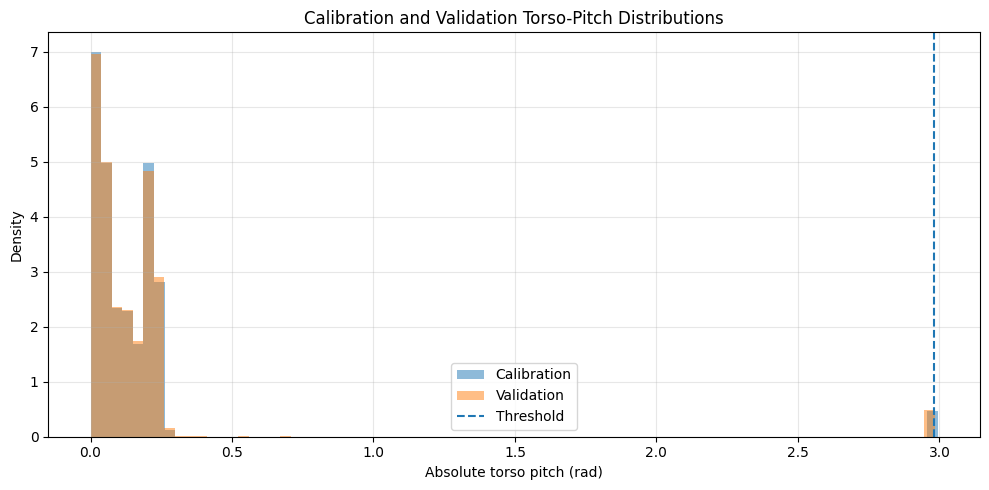

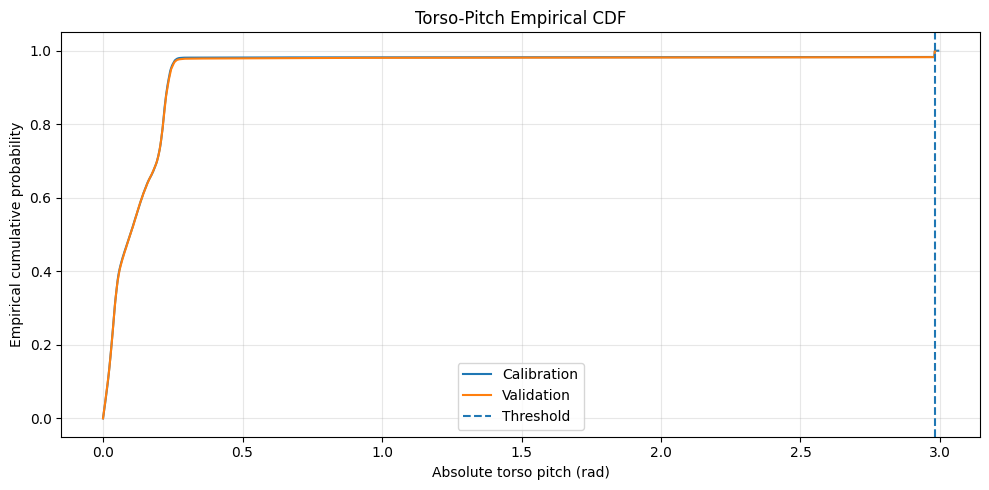

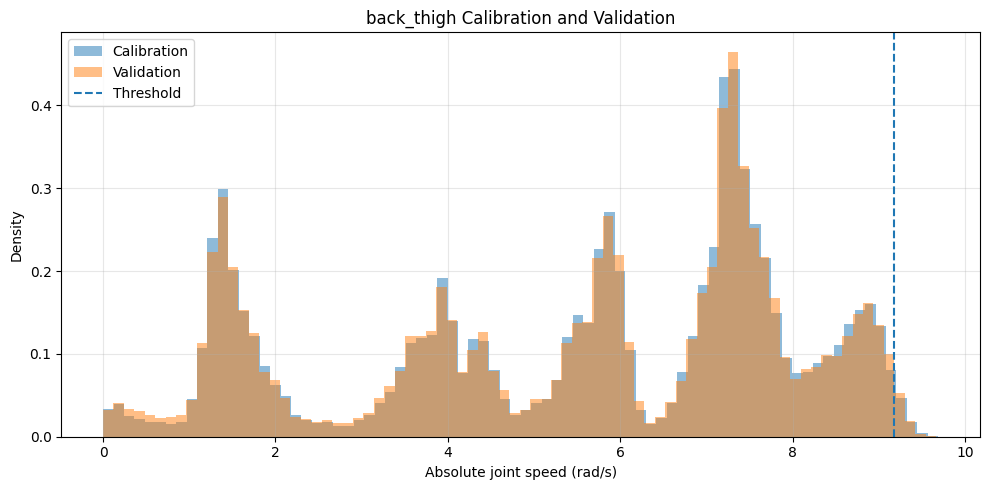

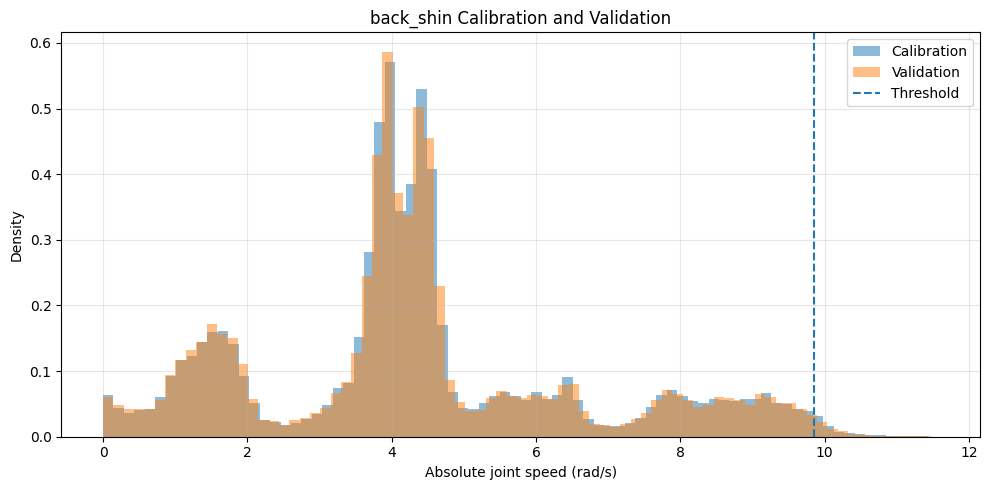

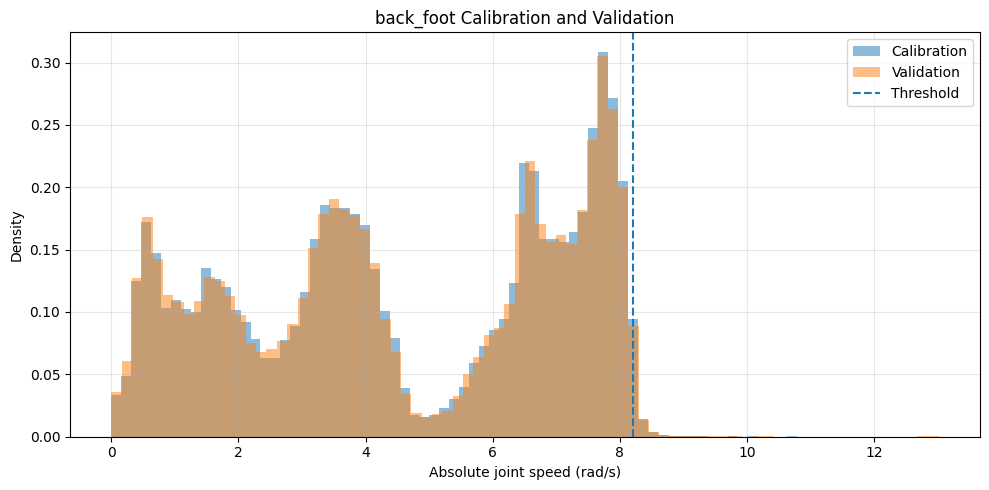

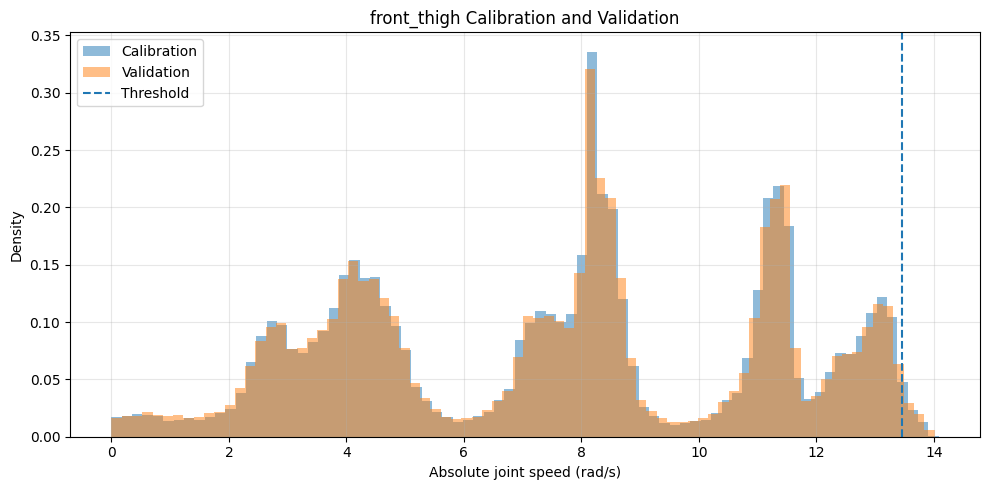

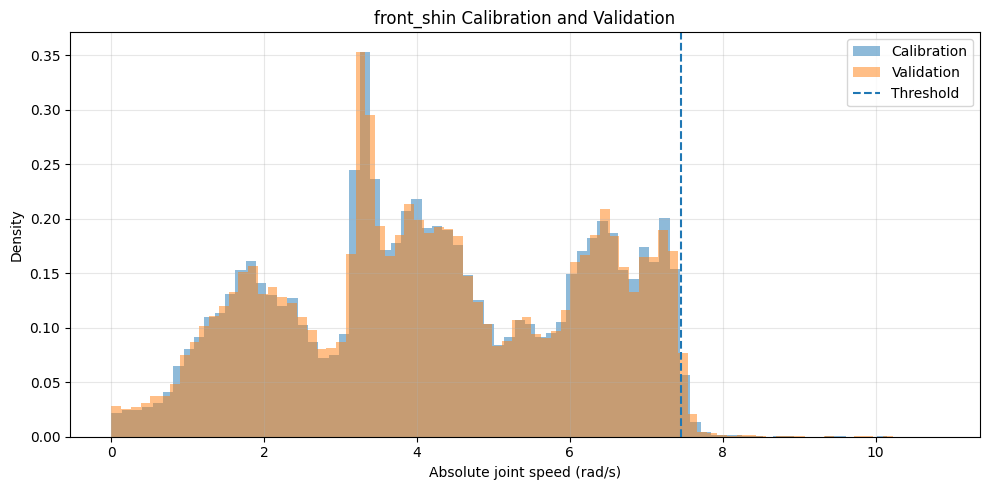

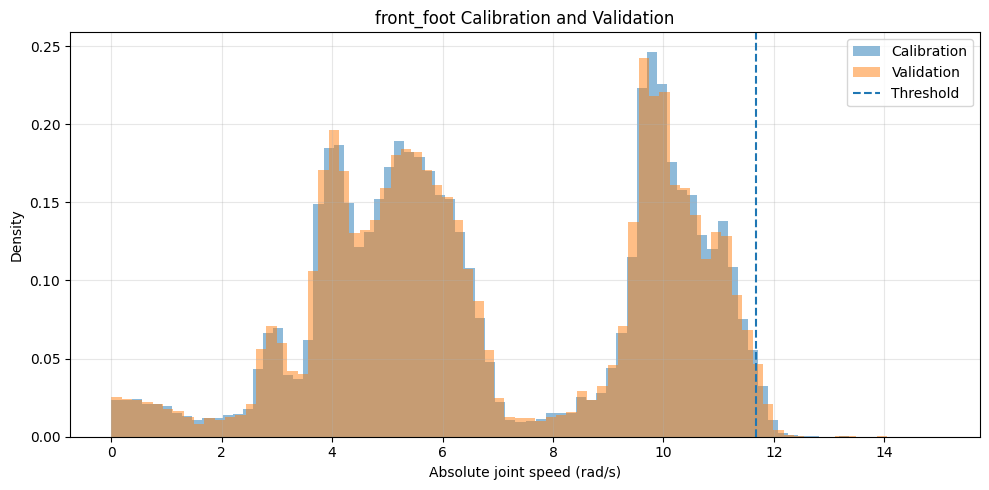

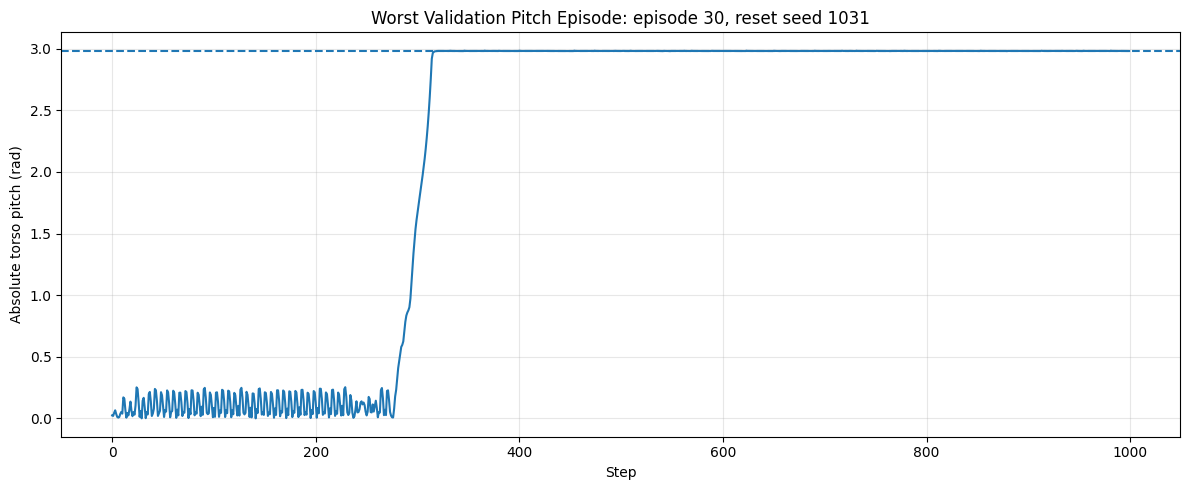

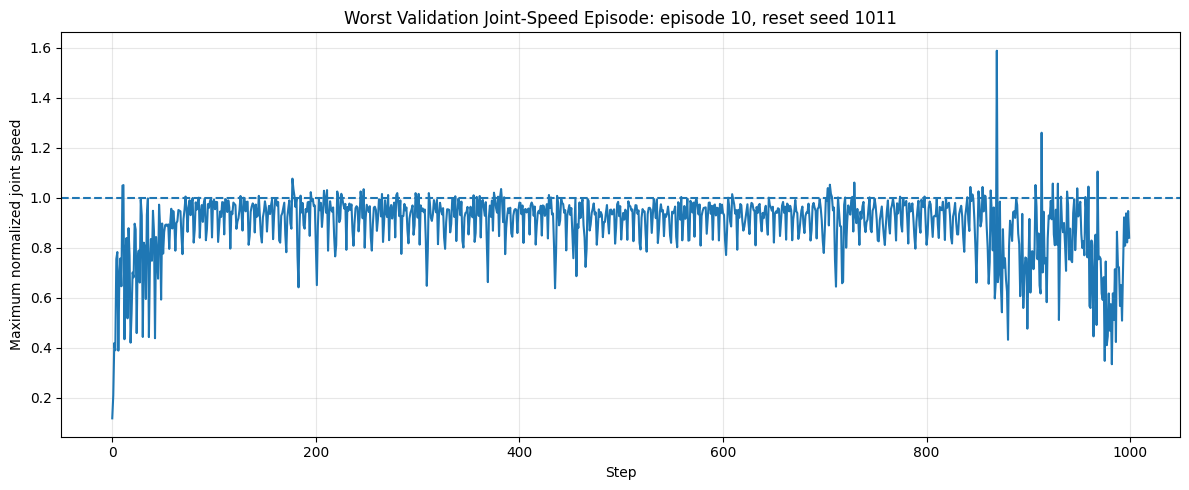

Calibration file: /home/bannanakid/RCRL_on_RCMDP/data_train/HalfCheetahWithPos/run3/metric_calibration/baseline_metrics.npz
Validation file: /home/bannanakid/RCRL_on_RCMDP/data_train/HalfCheetahWithPos/run3/metric_calibration/validation_metrics.npz
Calibration episodes: 100
Validation episodes: 50
Pitch threshold: 2.9807771443348865
Joint-speed thresholds: [ 9.17836024  9.84994114  8.20131241 13.4606267   7.45426533 11.68491498]
Pitch bootstrap: {'difference': -0.0009400000000000016, 'lower_95': -0.017462, 'upper_95': 0.01862}
Joint bootstrap: {'difference': 0.0005999999999999964, 'lower_95': -0.002699999999999987, 'upper_95': 0.003960249999999995}
                    category result
          Pitch distribution   PASS
Pitch episode violation rate   PASS
         Joint distributions   PASS
Joint episode violation rate   PASS
Results: /home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahWithPos/run3/threshold_validation


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/home/bannanakid/RCRL_on_RCMDP")
ENVIRONMENT_NAME = "HalfCheetahWithPos"
RUN_NUMBER = 3

CALIBRATION_FILE = (
    PROJECT_ROOT
    / "data_train"
    / ENVIRONMENT_NAME
    / f"run{RUN_NUMBER}"
    / "metric_calibration"
    / "baseline_metrics.npz"
)

VALIDATION_FILE = (
    PROJECT_ROOT
    / "data_train"
    / ENVIRONMENT_NAME
    / f"run{RUN_NUMBER}"
    / "metric_calibration"
    / "validation_metrics.npz"
)

PITCH_PERCENTILE = 99.0
JOINT_SPEED_PERCENTILE = 99.0

PITCH_THRESHOLD_OVERRIDE = None
JOINT_SPEED_THRESHOLDS_OVERRIDE = None

QUANTILE_RELATIVE_TOLERANCE = 0.10
TIMESTEP_VIOLATION_ABSOLUTE_TOLERANCE = 0.01
EPISODE_VIOLATION_ABSOLUTE_TOLERANCE = 0.02
KS_STATISTIC_TOLERANCE = 0.10
NORMALIZED_WASSERSTEIN_TOLERANCE = 0.20

BOOTSTRAP_SAMPLES = 5000
BOOTSTRAP_RANDOM_SEED = 2026

OUTPUT_DIRECTORY = (
    PROJECT_ROOT
    / "plot_data"
    / ENVIRONMENT_NAME
    / f"run{RUN_NUMBER}"
    / "threshold_validation"
)


def load_metric_file(path):
    if not path.exists():
        raise FileNotFoundError(path)
    with np.load(path, allow_pickle=False) as data:
        return {key: data[key].copy() for key in data.files}


def validate_metric_data(data):
    required = {
        "joint_names",
        "torso_pitch",
        "torso_pitch_abs",
        "joint_speeds",
        "episode_id",
        "step_in_episode",
        "seed",
    }
    missing = required.difference(data)
    if missing:
        raise KeyError(sorted(missing))
    if data["torso_pitch"].ndim != 1:
        raise ValueError("torso_pitch must be one-dimensional")
    if data["joint_speeds"].ndim != 2:
        raise ValueError("joint_speeds must be two-dimensional")
    if data["joint_speeds"].shape[1] != 6:
        raise ValueError("joint_speeds must contain six columns")
    if data["joint_speeds"].shape[0] != data["torso_pitch"].shape[0]:
        raise ValueError("metric sample counts do not match")
    if data["episode_id"].shape != data["torso_pitch"].shape:
        raise ValueError("episode_id shape does not match")
    if data["step_in_episode"].shape != data["torso_pitch"].shape:
        raise ValueError("step_in_episode shape does not match")


def empirical_cdf(values):
    sorted_values = np.sort(np.asarray(values, dtype=np.float64))
    probabilities = np.arange(1, sorted_values.size + 1) / sorted_values.size
    return sorted_values, probabilities


def ks_statistic(first, second):
    first = np.sort(np.asarray(first, dtype=np.float64))
    second = np.sort(np.asarray(second, dtype=np.float64))
    combined = np.sort(np.concatenate([first, second]))
    first_cdf = np.searchsorted(first, combined, side="right") / first.size
    second_cdf = np.searchsorted(second, combined, side="right") / second.size
    return float(np.max(np.abs(first_cdf - second_cdf)))


def normalized_wasserstein(first, second):
    first = np.asarray(first, dtype=np.float64)
    second = np.asarray(second, dtype=np.float64)
    probabilities = np.linspace(0.0, 1.0, 2001)
    first_quantiles = np.quantile(first, probabilities)
    second_quantiles = np.quantile(second, probabilities)
    distance = float(np.mean(np.abs(first_quantiles - second_quantiles)))
    scale = float(np.percentile(first, 75) - np.percentile(first, 25))
    if scale <= 1e-12:
        scale = float(np.std(first))
    if scale <= 1e-12:
        scale = 1.0
    return distance / scale


def relative_difference(reference, comparison):
    denominator = max(abs(float(reference)), 1e-12)
    return abs(float(comparison) - float(reference)) / denominator


def longest_true_run(values):
    values = np.asarray(values, dtype=bool)
    longest = 0
    current = 0
    for value in values:
        if value:
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest


def episode_scalar_statistics(values, episode_ids, threshold):
    values = np.asarray(values, dtype=np.float64)
    episode_ids = np.asarray(episode_ids, dtype=np.int64)
    rows = []
    for episode in np.unique(episode_ids):
        episode_values = values[episode_ids == episode]
        violations = episode_values > threshold
        rows.append(
            {
                "episode_id": int(episode),
                "mean": float(np.mean(episode_values)),
                "p95": float(np.percentile(episode_values, 95)),
                "p99": float(np.percentile(episode_values, 99)),
                "maximum": float(np.max(episode_values)),
                "violation_fraction": float(np.mean(violations)),
                "has_violation": bool(np.any(violations)),
                "longest_violation_run": int(longest_true_run(violations)),
            }
        )
    return pd.DataFrame(rows)


def episode_vector_statistics(values, episode_ids, thresholds):
    values = np.asarray(values, dtype=np.float64)
    episode_ids = np.asarray(episode_ids, dtype=np.int64)
    thresholds = np.asarray(thresholds, dtype=np.float64)
    normalized = values / thresholds
    step_max_ratio = np.max(normalized, axis=1)
    rows = []
    for episode in np.unique(episode_ids):
        episode_values = step_max_ratio[episode_ids == episode]
        violations = episode_values > 1.0
        rows.append(
            {
                "episode_id": int(episode),
                "mean_max_ratio": float(np.mean(episode_values)),
                "p95_max_ratio": float(np.percentile(episode_values, 95)),
                "p99_max_ratio": float(np.percentile(episode_values, 99)),
                "maximum_ratio": float(np.max(episode_values)),
                "violation_fraction": float(np.mean(violations)),
                "has_violation": bool(np.any(violations)),
                "longest_violation_run": int(longest_true_run(violations)),
            }
        )
    return pd.DataFrame(rows)


def bootstrap_mean_difference(first, second, samples, seed):
    first = np.asarray(first, dtype=np.float64)
    second = np.asarray(second, dtype=np.float64)
    generator = np.random.default_rng(seed)
    differences = np.empty(samples, dtype=np.float64)
    for index in range(samples):
        first_sample = generator.choice(first, size=first.size, replace=True)
        second_sample = generator.choice(second, size=second.size, replace=True)
        differences[index] = np.mean(second_sample) - np.mean(first_sample)
    return {
        "difference": float(np.mean(second) - np.mean(first)),
        "lower_95": float(np.percentile(differences, 2.5)),
        "upper_95": float(np.percentile(differences, 97.5)),
    }


def save_current_figure(filename):
    path = OUTPUT_DIRECTORY / filename
    plt.tight_layout()
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    return path


def top_pitch_events(data, dataset_name, threshold, count=20):
    values = data["torso_pitch_abs"]
    order = np.argsort(values)[::-1][:count]
    base_seed = int(data["seed"])
    return pd.DataFrame(
        {
            "dataset": dataset_name,
            "episode_id": data["episode_id"][order],
            "reset_seed": base_seed + data["episode_id"][order],
            "step_in_episode": data["step_in_episode"][order],
            "absolute_pitch_rad": values[order],
            "absolute_pitch_deg": np.degrees(values[order]),
            "threshold_rad": threshold,
            "excess_rad": np.maximum(values[order] - threshold, 0.0),
        }
    )


def top_joint_events(data, dataset_name, thresholds, joint_names, count=20):
    speeds = data["joint_speeds"]
    normalized = speeds / thresholds
    flat_order = np.argsort(normalized, axis=None)[::-1][:count]
    step_indices, joint_indices = np.unravel_index(flat_order, normalized.shape)
    base_seed = int(data["seed"])
    return pd.DataFrame(
        {
            "dataset": dataset_name,
            "episode_id": data["episode_id"][step_indices],
            "reset_seed": base_seed + data["episode_id"][step_indices],
            "step_in_episode": data["step_in_episode"][step_indices],
            "joint": [joint_names[index] for index in joint_indices],
            "joint_speed_rad_s": speeds[step_indices, joint_indices],
            "threshold_rad_s": thresholds[joint_indices],
            "threshold_ratio": normalized[step_indices, joint_indices],
        }
    )


def run_analysis():
    OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

    calibration = load_metric_file(CALIBRATION_FILE)
    validation = load_metric_file(VALIDATION_FILE)

    validate_metric_data(calibration)
    validate_metric_data(validation)

    joint_names = tuple(calibration["joint_names"].tolist())
    validation_joint_names = tuple(validation["joint_names"].tolist())

    if joint_names != validation_joint_names:
        raise ValueError("Calibration and validation joint orders differ")

    calibration_pitch = calibration["torso_pitch_abs"]
    validation_pitch = validation["torso_pitch_abs"]
    calibration_joint_speeds = calibration["joint_speeds"]
    validation_joint_speeds = validation["joint_speeds"]

    if PITCH_THRESHOLD_OVERRIDE is None:
        pitch_threshold = float(
            np.percentile(calibration_pitch, PITCH_PERCENTILE)
        )
    else:
        pitch_threshold = float(PITCH_THRESHOLD_OVERRIDE)

    if JOINT_SPEED_THRESHOLDS_OVERRIDE is None:
        joint_speed_thresholds = np.percentile(
            calibration_joint_speeds,
            JOINT_SPEED_PERCENTILE,
            axis=0,
        )
    else:
        joint_speed_thresholds = np.asarray(
            JOINT_SPEED_THRESHOLDS_OVERRIDE,
            dtype=np.float64,
        )

    if joint_speed_thresholds.shape != (6,):
        raise ValueError(
            "JOINT_SPEED_THRESHOLDS_OVERRIDE must contain six values"
        )

    threshold_table = pd.DataFrame(
        {
            "metric": ("torso_pitch",) + joint_names,
            "threshold": (pitch_threshold,) + tuple(joint_speed_thresholds),
            "units": ("rad",) + ("rad/s",) * 6,
            "source": (
                "manual"
                if PITCH_THRESHOLD_OVERRIDE is not None
                else f"calibration_p{PITCH_PERCENTILE:g}"
            ,)
            + tuple(
                "manual"
                if JOINT_SPEED_THRESHOLDS_OVERRIDE is not None
                else f"calibration_p{JOINT_SPEED_PERCENTILE:g}"
                for _ in joint_names
            ),
        }
    )

    pitch_distribution_rows = []
    for percentile in (50, 90, 95, 99):
        calibration_value = float(
            np.percentile(calibration_pitch, percentile)
        )
        validation_value = float(
            np.percentile(validation_pitch, percentile)
        )
        pitch_distribution_rows.append(
            {
                "metric": f"p{percentile}",
                "calibration": calibration_value,
                "validation": validation_value,
                "absolute_difference": validation_value - calibration_value,
                "relative_difference": relative_difference(
                    calibration_value,
                    validation_value,
                ),
            }
        )

    pitch_distribution_rows.extend(
        [
            {
                "metric": "mean",
                "calibration": float(np.mean(calibration_pitch)),
                "validation": float(np.mean(validation_pitch)),
                "absolute_difference": float(
                    np.mean(validation_pitch) - np.mean(calibration_pitch)
                ),
                "relative_difference": relative_difference(
                    np.mean(calibration_pitch),
                    np.mean(validation_pitch),
                ),
            },
            {
                "metric": "maximum",
                "calibration": float(np.max(calibration_pitch)),
                "validation": float(np.max(validation_pitch)),
                "absolute_difference": float(
                    np.max(validation_pitch) - np.max(calibration_pitch)
                ),
                "relative_difference": relative_difference(
                    np.max(calibration_pitch),
                    np.max(validation_pitch),
                ),
            },
        ]
    )

    pitch_distribution_table = pd.DataFrame(pitch_distribution_rows)

    pitch_ks = ks_statistic(calibration_pitch, validation_pitch)
    pitch_wasserstein = normalized_wasserstein(
        calibration_pitch,
        validation_pitch,
    )
    pitch_calibration_timestep_violation = float(
        np.mean(calibration_pitch > pitch_threshold)
    )
    pitch_validation_timestep_violation = float(
        np.mean(validation_pitch > pitch_threshold)
    )

    calibration_pitch_episodes = episode_scalar_statistics(
        calibration_pitch,
        calibration["episode_id"],
        pitch_threshold,
    )
    validation_pitch_episodes = episode_scalar_statistics(
        validation_pitch,
        validation["episode_id"],
        pitch_threshold,
    )

    pitch_bootstrap = bootstrap_mean_difference(
        calibration_pitch_episodes["violation_fraction"],
        validation_pitch_episodes["violation_fraction"],
        BOOTSTRAP_SAMPLES,
        BOOTSTRAP_RANDOM_SEED,
    )

    pitch_similarity_table = pd.DataFrame(
        {
            "check": [
                "KS statistic",
                "Normalized Wasserstein distance",
                "P99 relative difference",
                "Timestep violation-rate difference",
                "Episode mean violation-rate difference",
            ],
            "value": [
                pitch_ks,
                pitch_wasserstein,
                relative_difference(
                    np.percentile(calibration_pitch, 99),
                    np.percentile(validation_pitch, 99),
                ),
                abs(
                    pitch_validation_timestep_violation
                    - pitch_calibration_timestep_violation
                ),
                abs(pitch_bootstrap["difference"]),
            ],
            "tolerance": [
                KS_STATISTIC_TOLERANCE,
                NORMALIZED_WASSERSTEIN_TOLERANCE,
                QUANTILE_RELATIVE_TOLERANCE,
                TIMESTEP_VIOLATION_ABSOLUTE_TOLERANCE,
                EPISODE_VIOLATION_ABSOLUTE_TOLERANCE,
            ],
        }
    )
    pitch_similarity_table["result"] = np.where(
        pitch_similarity_table["value"]
        <= pitch_similarity_table["tolerance"],
        "PASS",
        "REVIEW",
    )

    pitch_violation_summary = pd.DataFrame(
        {
            "dataset": ["calibration", "validation"],
            "timestep_violation_fraction": [
                pitch_calibration_timestep_violation,
                pitch_validation_timestep_violation,
            ],
            "mean_episode_violation_fraction": [
                calibration_pitch_episodes["violation_fraction"].mean(),
                validation_pitch_episodes["violation_fraction"].mean(),
            ],
            "median_episode_violation_fraction": [
                calibration_pitch_episodes["violation_fraction"].median(),
                validation_pitch_episodes["violation_fraction"].median(),
            ],
            "episodes_with_any_violation_fraction": [
                calibration_pitch_episodes["has_violation"].mean(),
                validation_pitch_episodes["has_violation"].mean(),
            ],
            "mean_longest_violation_run": [
                calibration_pitch_episodes["longest_violation_run"].mean(),
                validation_pitch_episodes["longest_violation_run"].mean(),
            ],
            "maximum_longest_violation_run": [
                calibration_pitch_episodes["longest_violation_run"].max(),
                validation_pitch_episodes["longest_violation_run"].max(),
            ],
        }
    )

    joint_distribution_rows = []
    for index, joint_name in enumerate(joint_names):
        calibration_values = calibration_joint_speeds[:, index]
        validation_values = validation_joint_speeds[:, index]
        joint_distribution_rows.append(
            {
                "joint": joint_name,
                "calibration_p95": np.percentile(
                    calibration_values,
                    95,
                ),
                "validation_p95": np.percentile(
                    validation_values,
                    95,
                ),
                "p95_relative_difference": relative_difference(
                    np.percentile(calibration_values, 95),
                    np.percentile(validation_values, 95),
                ),
                "calibration_p99": np.percentile(
                    calibration_values,
                    99,
                ),
                "validation_p99": np.percentile(
                    validation_values,
                    99,
                ),
                "p99_relative_difference": relative_difference(
                    np.percentile(calibration_values, 99),
                    np.percentile(validation_values, 99),
                ),
                "calibration_max": np.max(calibration_values),
                "validation_max": np.max(validation_values),
                "ks_statistic": ks_statistic(
                    calibration_values,
                    validation_values,
                ),
                "normalized_wasserstein": normalized_wasserstein(
                    calibration_values,
                    validation_values,
                ),
                "calibration_timestep_violation_fraction": np.mean(
                    calibration_values > joint_speed_thresholds[index]
                ),
                "validation_timestep_violation_fraction": np.mean(
                    validation_values > joint_speed_thresholds[index]
                ),
            }
        )

    joint_distribution_table = pd.DataFrame(
        joint_distribution_rows
    ).set_index("joint")

    calibration_joint_normalized = (
        calibration_joint_speeds / joint_speed_thresholds
    )
    validation_joint_normalized = (
        validation_joint_speeds / joint_speed_thresholds
    )

    calibration_any_joint_violation = np.any(
        calibration_joint_normalized > 1.0,
        axis=1,
    )
    validation_any_joint_violation = np.any(
        validation_joint_normalized > 1.0,
        axis=1,
    )

    calibration_joint_episodes = episode_vector_statistics(
        calibration_joint_speeds,
        calibration["episode_id"],
        joint_speed_thresholds,
    )
    validation_joint_episodes = episode_vector_statistics(
        validation_joint_speeds,
        validation["episode_id"],
        joint_speed_thresholds,
    )

    joint_bootstrap = bootstrap_mean_difference(
        calibration_joint_episodes["violation_fraction"],
        validation_joint_episodes["violation_fraction"],
        BOOTSTRAP_SAMPLES,
        BOOTSTRAP_RANDOM_SEED + 1,
    )

    joint_violation_summary = pd.DataFrame(
        {
            "dataset": ["calibration", "validation"],
            "any_joint_timestep_violation_fraction": [
                np.mean(calibration_any_joint_violation),
                np.mean(validation_any_joint_violation),
            ],
            "mean_episode_violation_fraction": [
                calibration_joint_episodes["violation_fraction"].mean(),
                validation_joint_episodes["violation_fraction"].mean(),
            ],
            "median_episode_violation_fraction": [
                calibration_joint_episodes["violation_fraction"].median(),
                validation_joint_episodes["violation_fraction"].median(),
            ],
            "episodes_with_any_violation_fraction": [
                calibration_joint_episodes["has_violation"].mean(),
                validation_joint_episodes["has_violation"].mean(),
            ],
            "mean_longest_violation_run": [
                calibration_joint_episodes["longest_violation_run"].mean(),
                validation_joint_episodes["longest_violation_run"].mean(),
            ],
            "maximum_longest_violation_run": [
                calibration_joint_episodes["longest_violation_run"].max(),
                validation_joint_episodes["longest_violation_run"].max(),
            ],
        }
    )

    joint_similarity_rows = []
    for joint_name, row in joint_distribution_table.iterrows():
        joint_similarity_rows.append(
            {
                "metric": joint_name,
                "p99_relative_difference": row[
                    "p99_relative_difference"
                ],
                "p99_result": (
                    "PASS"
                    if row["p99_relative_difference"]
                    <= QUANTILE_RELATIVE_TOLERANCE
                    else "REVIEW"
                ),
                "ks_statistic": row["ks_statistic"],
                "ks_result": (
                    "PASS"
                    if row["ks_statistic"] <= KS_STATISTIC_TOLERANCE
                    else "REVIEW"
                ),
                "normalized_wasserstein": row[
                    "normalized_wasserstein"
                ],
                "wasserstein_result": (
                    "PASS"
                    if row["normalized_wasserstein"]
                    <= NORMALIZED_WASSERSTEIN_TOLERANCE
                    else "REVIEW"
                ),
                "violation_rate_difference": abs(
                    row["validation_timestep_violation_fraction"]
                    - row["calibration_timestep_violation_fraction"]
                ),
                "violation_result": (
                    "PASS"
                    if abs(
                        row["validation_timestep_violation_fraction"]
                        - row[
                            "calibration_timestep_violation_fraction"
                        ]
                    )
                    <= TIMESTEP_VIOLATION_ABSOLUTE_TOLERANCE
                    else "REVIEW"
                ),
            }
        )

    joint_similarity_table = pd.DataFrame(
        joint_similarity_rows
    ).set_index("metric")

    pitch_events = pd.concat(
        [
            top_pitch_events(
                calibration,
                "calibration",
                pitch_threshold,
            ),
            top_pitch_events(
                validation,
                "validation",
                pitch_threshold,
            ),
        ],
        ignore_index=True,
    )

    joint_events = pd.concat(
        [
            top_joint_events(
                calibration,
                "calibration",
                joint_speed_thresholds,
                joint_names,
            ),
            top_joint_events(
                validation,
                "validation",
                joint_speed_thresholds,
                joint_names,
            ),
        ],
        ignore_index=True,
    )

    overall_results = pd.DataFrame(
        {
            "category": [
                "Pitch distribution",
                "Pitch episode violation rate",
                "Joint distributions",
                "Joint episode violation rate",
            ],
            "result": [
                (
                    "PASS"
                    if (pitch_similarity_table["result"] == "PASS").all()
                    else "REVIEW"
                ),
                (
                    "PASS"
                    if abs(pitch_bootstrap["difference"])
                    <= EPISODE_VIOLATION_ABSOLUTE_TOLERANCE
                    else "REVIEW"
                ),
                (
                    "PASS"
                    if (
                        joint_similarity_table[
                            [
                                "p99_result",
                                "ks_result",
                                "wasserstein_result",
                            ]
                        ]
                        == "PASS"
                    ).all().all()
                    else "REVIEW"
                ),
                (
                    "PASS"
                    if abs(joint_bootstrap["difference"])
                    <= EPISODE_VIOLATION_ABSOLUTE_TOLERANCE
                    else "REVIEW"
                ),
            ],
        }
    )

    threshold_table.to_csv(
        OUTPUT_DIRECTORY / "thresholds.csv",
        index=False,
    )
    pitch_distribution_table.to_csv(
        OUTPUT_DIRECTORY / "pitch_distribution_comparison.csv",
        index=False,
    )
    pitch_similarity_table.to_csv(
        OUTPUT_DIRECTORY / "pitch_similarity_checks.csv",
        index=False,
    )
    pitch_violation_summary.to_csv(
        OUTPUT_DIRECTORY / "pitch_violation_summary.csv",
        index=False,
    )
    calibration_pitch_episodes.to_csv(
        OUTPUT_DIRECTORY / "calibration_pitch_episode_metrics.csv",
        index=False,
    )
    validation_pitch_episodes.to_csv(
        OUTPUT_DIRECTORY / "validation_pitch_episode_metrics.csv",
        index=False,
    )
    joint_distribution_table.to_csv(
        OUTPUT_DIRECTORY / "joint_distribution_comparison.csv"
    )
    joint_similarity_table.to_csv(
        OUTPUT_DIRECTORY / "joint_similarity_checks.csv"
    )
    joint_violation_summary.to_csv(
        OUTPUT_DIRECTORY / "joint_violation_summary.csv",
        index=False,
    )
    calibration_joint_episodes.to_csv(
        OUTPUT_DIRECTORY / "calibration_joint_episode_metrics.csv",
        index=False,
    )
    validation_joint_episodes.to_csv(
        OUTPUT_DIRECTORY / "validation_joint_episode_metrics.csv",
        index=False,
    )
    pitch_events.to_csv(
        OUTPUT_DIRECTORY / "top_pitch_events.csv",
        index=False,
    )
    joint_events.to_csv(
        OUTPUT_DIRECTORY / "top_joint_speed_events.csv",
        index=False,
    )
    overall_results.to_csv(
        OUTPUT_DIRECTORY / "overall_similarity_result.csv",
        index=False,
    )

    plt.figure(figsize=(10, 5))
    plt.hist(
        calibration_pitch,
        bins=80,
        density=True,
        alpha=0.5,
        label="Calibration",
    )
    plt.hist(
        validation_pitch,
        bins=80,
        density=True,
        alpha=0.5,
        label="Validation",
    )
    plt.axvline(pitch_threshold, linestyle="--", label="Threshold")
    plt.xlabel("Absolute torso pitch (rad)")
    plt.ylabel("Density")
    plt.title("Calibration and Validation Torso-Pitch Distributions")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_current_figure("pitch_distribution_overlay.png")

    calibration_x, calibration_y = empirical_cdf(calibration_pitch)
    validation_x, validation_y = empirical_cdf(validation_pitch)

    plt.figure(figsize=(10, 5))
    plt.plot(calibration_x, calibration_y, label="Calibration")
    plt.plot(validation_x, validation_y, label="Validation")
    plt.axvline(pitch_threshold, linestyle="--", label="Threshold")
    plt.xlabel("Absolute torso pitch (rad)")
    plt.ylabel("Empirical cumulative probability")
    plt.title("Torso-Pitch Empirical CDF")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_current_figure("pitch_ecdf_overlay.png")

    for index, joint_name in enumerate(joint_names):
        plt.figure(figsize=(10, 5))
        plt.hist(
            calibration_joint_speeds[:, index],
            bins=80,
            density=True,
            alpha=0.5,
            label="Calibration",
        )
        plt.hist(
            validation_joint_speeds[:, index],
            bins=80,
            density=True,
            alpha=0.5,
            label="Validation",
        )
        plt.axvline(
            joint_speed_thresholds[index],
            linestyle="--",
            label="Threshold",
        )
        plt.xlabel("Absolute joint speed (rad/s)")
        plt.ylabel("Density")
        plt.title(f"{joint_name} Calibration and Validation")
        plt.legend()
        plt.grid(True, alpha=0.3)
        save_current_figure(f"{joint_name}_distribution_overlay.png")

    worst_validation_pitch_episode = int(
        validation_pitch_episodes.sort_values(
            "maximum",
            ascending=False,
        ).iloc[0]["episode_id"]
    )
    pitch_mask = (
        validation["episode_id"] == worst_validation_pitch_episode
    )

    plt.figure(figsize=(12, 5))
    plt.plot(
        validation["step_in_episode"][pitch_mask],
        validation_pitch[pitch_mask],
    )
    plt.axhline(pitch_threshold, linestyle="--")
    plt.xlabel("Step")
    plt.ylabel("Absolute torso pitch (rad)")
    plt.title(
        f"Worst Validation Pitch Episode: episode "
        f"{worst_validation_pitch_episode}, reset seed "
        f"{int(validation['seed']) + worst_validation_pitch_episode}"
    )
    plt.grid(True, alpha=0.3)
    save_current_figure("worst_validation_pitch_episode.png")

    validation_step_max_joint_ratio = np.max(
        validation_joint_speeds / joint_speed_thresholds,
        axis=1,
    )
    worst_validation_joint_episode = int(
        validation_joint_episodes.sort_values(
            "maximum_ratio",
            ascending=False,
        ).iloc[0]["episode_id"]
    )
    joint_mask = (
        validation["episode_id"] == worst_validation_joint_episode
    )

    plt.figure(figsize=(12, 5))
    plt.plot(
        validation["step_in_episode"][joint_mask],
        validation_step_max_joint_ratio[joint_mask],
    )
    plt.axhline(1.0, linestyle="--")
    plt.xlabel("Step")
    plt.ylabel("Maximum normalized joint speed")
    plt.title(
        f"Worst Validation Joint-Speed Episode: episode "
        f"{worst_validation_joint_episode}, reset seed "
        f"{int(validation['seed']) + worst_validation_joint_episode}"
    )
    plt.grid(True, alpha=0.3)
    save_current_figure("worst_validation_joint_speed_episode.png")

    print("Calibration file:", CALIBRATION_FILE)
    print("Validation file:", VALIDATION_FILE)
    print("Calibration episodes:", np.unique(calibration["episode_id"]).size)
    print("Validation episodes:", np.unique(validation["episode_id"]).size)
    print("Pitch threshold:", pitch_threshold)
    print("Joint-speed thresholds:", joint_speed_thresholds)
    print("Pitch bootstrap:", pitch_bootstrap)
    print("Joint bootstrap:", joint_bootstrap)
    print(overall_results.to_string(index=False))
    print("Results:", OUTPUT_DIRECTORY)

    return {
        "thresholds": threshold_table,
        "pitch_distribution": pitch_distribution_table,
        "pitch_similarity": pitch_similarity_table,
        "pitch_violations": pitch_violation_summary,
        "joint_distribution": joint_distribution_table,
        "joint_similarity": joint_similarity_table,
        "joint_violations": joint_violation_summary,
        "pitch_events": pitch_events,
        "joint_events": joint_events,
        "overall_results": overall_results,
    }


if __name__ == "__main__":
    run_analysis()
